In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Income distribution: how does Italy's spread of income compare with the EU27?
Until now inequality was one Gini and a few poverty rates. Here the **shape**: shares of equivalised disposable income held by each quintile (and the bottom and top decile), the S80/S20 ratio, and the Ginis **before and after** social transfers (EU-SILC through Eurostat: `ilc_di01`, `ilc_di11`, `ilc_di12`, `ilc_di12b`, `ilc_di12c`; table `data/processed/income_dist.parquet`).
Method: country means over three windows (2005-09, 2015-19, 2021-25; breaks `b` and provisional `p` values dropped), Italy ranked among the 27 members, and judged by a **placebo ranking** (each country's gap to the median of the others, ranked against Italy's gap; `p_abs` = share of countries with an absolute gap at least as large), not a test with Italy as a cluster. Years are Eurostat survey years; incomes refer mostly to the previous calendar year. The disposable-income Gini starts in 2014, so redistribution can be measured only from 2015.
**Descriptive only**: this shows where Italy sits, not why. Code: `src/cifresignificative/studies/italy_productivity/analysis/income_dist.py`.

In [2]:
from cifresignificative.studies.italy_productivity.analysis import income_dist as ID
inc = ID.load_income()
W = ID.wide(inc)
print("rows:", len(inc), "| countries:", inc[inc.iso3.isin(EU27_ISO3)].iso3.nunique(), "| years:", inc.year.min(), "-", inc.year.max(), "| flags dropped:", sorted(ID.DROP_FLAGS))
tab = ID.italy_table(W)
show = tab.pivot(index="measure", columns="window", values=["value", "median_others", "rank_from_top", "p_abs"]).round(2)
display(show)
print("Italy's quintile shares minus the median of the others (pp), by window:")
display(pd.DataFrame({w: ID.shape_gap(W, win).gap for w, win in ID.WINDOWS.items()}).round(2))
print("Change in the window mean 2005-09 -> 2021-25 (Italy vs placebo ranking, 1 = largest rise):"); display(ID.change_table(W, (2005, 2009), (2021, 2025)).dropna().round(2))
print("calibration (shuffled countries, share with p_abs < 0.05):", ID.shuffled_null(W, (2015, 2019)))

rows: 6175 | countries: 27 | years: 2005 - 2025 | flags dropped: ['b', 'p']


value                 median_others                  \
window              2005-09 2015-19 2021-25       2005-09 2015-19 2021-25   
measure                                                                     
D1                     2.56    1.98    2.54          3.52    3.18    3.07   
D10                   24.48   24.50   24.58         23.15   23.10   23.15   
QU1                    7.30    6.56    7.20          8.98    8.50    8.36   
QU2                   12.90   12.86   12.92         13.85   13.51   13.69   
QU3                   17.48   17.72   17.52         17.62   17.70   17.71   
QU4                   23.02   23.34   22.92         22.62   22.76   22.66   
QU5                   39.30   39.52   39.42         37.30   37.81   37.23   
gini_disp               NaN   32.88   32.06           NaN   29.44   29.26   
gini_pre_pens_excl    33.54   35.26   36.08         35.34   35.50   34.26   
gini_pre_pens_incl    47.52   48.54   48.55         47.82   49.20   46.60   
redistribution_excl     NaN    6.75   11.57           NaN   13.31   12.40   
redistribution_incl     NaN   32.26   34.30           NaN   41.77   38.76   
s80_s20                5.39    6.03    5.48          4.10    4.51    4.50   

                    rank_from_top                   p_abs                  
window                    2005-09 2015-19 2021-25 2005-09 2015-19 2021-25  
measure                                                                    
D1                           20.0    26.0    22.0    0.27    0.07    0.56  
D10                           9.0     8.0     7.0    0.58    0.52    0.56  
QU1                          19.0    22.0    22.0    0.31    0.22    0.44  
QU2                          16.0    18.0    22.0    0.58    0.70    0.48  
QU3                          16.0    13.0    18.0    0.77    0.93    0.81  
QU4                           6.0     6.0    10.0    0.54    0.37    0.70  
QU5                           9.0     9.0     5.0    0.50    0.63    0.41  
gini_disp                     NaN     8.0     5.0     NaN    0.48    0.48  
gini_pre_pens_excl           17.0    15.0     6.0    0.65    0.96    0.59  
gini_pre_pens_incl           14.0    16.0    10.0    1.00    0.93    0.67  
redistribution_excl           NaN    27.0    16.0     NaN    0.22    0.89  
redistribution_incl           NaN    22.0    19.0     NaN    0.26    0.59  
s80_s20                       9.0     6.0     6.0    0.35    0.22    0.37

Italy's quintile shares minus the median of the others (pp), by window:


,2005-09,2015-19,2021-25
measure,,,
QU1,-1.68,-1.94,-1.16
QU2,-0.95,-0.65,-0.77
QU3,-0.14,0.02,-0.19
QU4,0.40,0.58,0.26
QU5,2.00,1.71,2.19


Change in the window mean 2005-09 -> 2021-25 (Italy vs placebo ranking, 1 = largest rise):


,measure,value,median_others,gap,rank_from_top,n_countries,p_abs
0,D1,-0.02,0.08,-0.10,17.0,26.0,0.73
1,D10,0.10,0.02,0.08,13.0,26.0,1.00
2,QU1,-0.10,-0.04,-0.06,17.0,26.0,0.85
3,QU2,0.02,0.08,-0.07,14.0,26.0,1.00
4,QU3,0.04,0.20,-0.16,16.0,26.0,0.85
5,QU4,-0.10,0.10,-0.20,17.0,26.0,0.69
6,QU5,0.12,0.00,0.12,13.0,26.0,1.00
8,gini_pre_pens_excl,2.53,-0.56,3.10,4.0,26.0,0.35
9,gini_pre_pens_incl,1.03,0.83,0.20,13.0,26.0,1.00
10,s80_s20,0.09,-0.02,0.11,10.0,26.0,0.81


calibration (shuffled countries, share with p_abs < 0.05): {'share_p_below_005': 0.034, 'n_rep': 500}


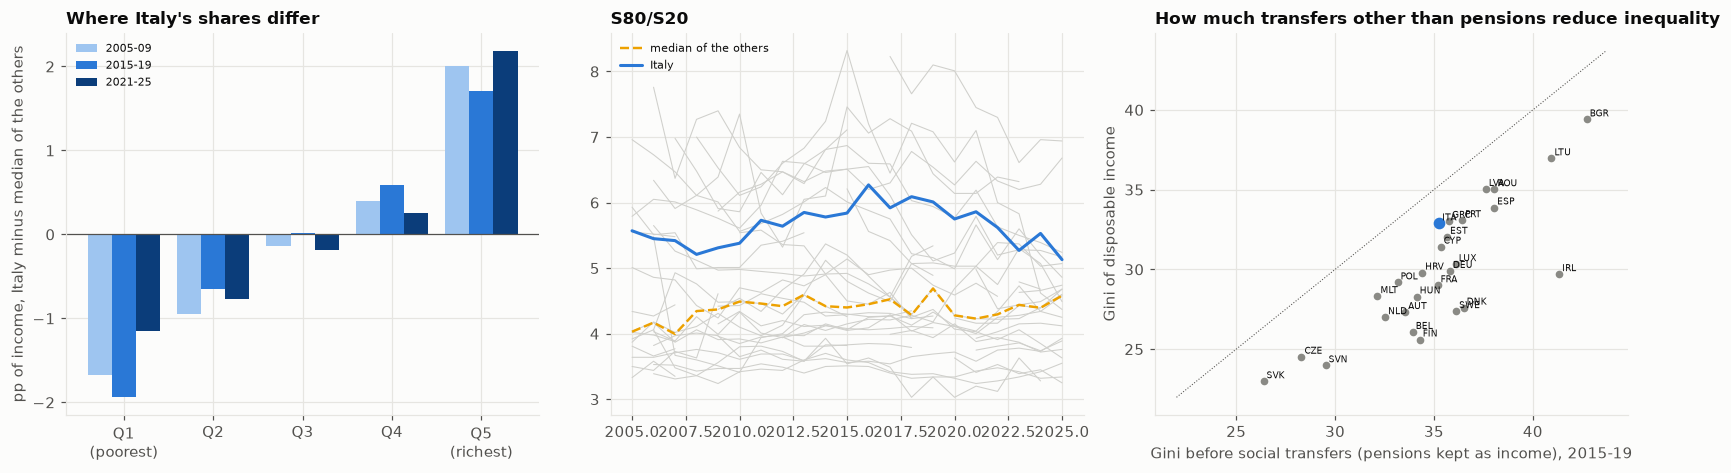

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]; w = 0.27
for k, (name, win) in enumerate(ID.WINDOWS.items()):
    g = ID.shape_gap(W, win).gap; ax.bar(np.arange(5) + (k - 1) * w, g.values, w, label=name, color=["#9ec5f0", "#2a78d6", "#0b3d7a"][k])
ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(range(5), ["Q1\n(poorest)", "Q2", "Q3", "Q4", "Q5\n(richest)"]); ax.set_ylabel("pp of income, Italy minus median of the others"); ax.set_title("Where Italy's shares differ"); ax.legend(fontsize=7)
ax = axes[1]; s = W["s80_s20"].unstack("iso3")
for c in s: ax.plot(s.index, s[c], color="#d0d0cc", lw=0.7)
oth = s.drop(columns=ITALY).median(axis=1); ax.plot(s.index, oth, color="#eda100", ls="--", lw=1.6, label="median of the others"); ax.plot(s.index, s[ITALY], color=ITALY_C, lw=2, label="Italy"); ax.set_title("S80/S20"); ax.legend(fontsize=7)
ax = axes[2]; T = ID.window_table(W, ID.WINDOWS["2015-19"]).dropna(subset=["gini_pre_pens_excl", "gini_disp"])
for c in T.index: ax.scatter(T.loc[c, "gini_pre_pens_excl"], T.loc[c, "gini_disp"], color=ITALY_C if c == ITALY else "#8a8a85", s=44 if c == ITALY else 16, zorder=3 if c == ITALY else 2); ax.annotate(c, (T.loc[c, "gini_pre_pens_excl"], T.loc[c, "gini_disp"]), fontsize=6, xytext=(2, 2), textcoords="offset points")
lim = [T[["gini_pre_pens_excl", "gini_disp"]].min().min() - 1, T[["gini_pre_pens_excl", "gini_disp"]].max().max() + 1]; ax.plot(lim, lim, color=INK2, lw=0.7, ls=":")
ax.set_xlabel("Gini before social transfers (pensions kept as income), 2015-19"); ax.set_ylabel("Gini of disposable income"); ax.set_title("How much transfers other than pensions reduce inequality")
fig.tight_layout(); save(fig, "30_income_distribution")

## Takeaways (EU-SILC via Eurostat, survey years 2005-2025; descriptive, cross-country)
- **The shape: thin bottom, heavy top, middle on par.** Italy's bottom quintile holds 1.7 pp less of income than the median of the other members in 2005-09 (7.3% vs 9.0%), 1.9 pp less in 2015-19 (6.6% vs 8.5%) and 1.2 pp less in 2021-25 (7.2% vs 8.4%); the top quintile holds 2.0, 1.7 and 2.2 pp more (39.3-39.5% vs 37.2-37.8%); the middle quintile is within 0.2 pp. S80/S20 is 5.4, 6.0 and 5.5 against a median of 4.1, 4.5 and 4.5 (Italy ranks 9th of 26, then 6th of 27 twice, 1 = most unequal); the Gini of disposable income (available from 2014) is 32.9 vs 29.4 in 2015-19 and 32.1 vs 29.3 in 2021-25 (5th highest).
- **But no placebo ranking singles Italy out.** Italy's gap to the median is ranked against every country's own gap: the share of countries with a gap at least as large (`p_abs`) is 0.22-0.37 for S80/S20 and 0.48 for the Gini; the smallest value in the table is 0.07 for the bottom decile in 2015-19 (Italy 26th of 27, 2.0% of income vs 3.2%), which does not stand out given the number of cells read. Italy is moderately more unequal than the typical member, with several others further out (on S80/S20 in 2015-19: Bulgaria, Romania, Lithuania, Latvia and Spain; on the disposable Gini in 2021-25: Bulgaria, Lithuania, Latvia and Portugal).
- **Little change in shape since 2005-09.** Italy's rise in S80/S20 (+0.09 between the window means) and in each quintile share is ordinary against the other countries (all `p_abs` >= 0.35; 26 countries with both windows); the early-2010s deterioration and the 2022-25 improvement roughly offset in the means (S80/S20 6.3 in 2016, 5.1 in 2025).
- **Redistribution is where Italy is weakest, depending on the definition.** Counting pensions as income (so only other transfers redistribute), the Gini falls 6.7% from before transfers to disposable income in 2015-19, the lowest of the 27 (median of the others 13.3%, range 6.9-28.1%; `p_abs` 0.22); in 2021-25 it is 11.6% (16th, median 12.4%), after the pandemic-era transfers. Counting pensions as transfers, the fall is 32% against 42% in 2015-19 (22nd of 27) and 34% against 39% in 2021-25 (19th). The pre-transfer Gini (pensions as income) rose 2.5 points from 2005-09 to 2021-25 against a median change of -0.6 (4th largest rise of 26, `p_abs` 0.35).
- **Limits.** Survey years, not income years; the disposable-income Gini starts in 2014, so redistribution is only measured from 2015; pre-transfer measures are conventions (pensions in or out) rather than a counterfactual without the welfare state, since behaviour would differ; EU-SILC under-covers the very rich and the very poor (top shares from tax data would be higher); Italy's 2022 pre-transfer values carry a break flag and are dropped; about a hundred cells were read, so isolated p_abs values near 0.05 are expected by chance. Descriptive: it says where Italy sits, not why.
